In [5]:
import jax
import jax.numpy as jnp

DT = 0.1          # must match the ROS timer period
H = 30            # horizon: 3 s
K = 512           # samples per tick
LAMBDA = 1.0      # MPPI temperature: lower = trust the best sample more
V_MAX, W_MAX = 0.22, 2.0          # check your model's spec sheet
NOISE_STD = jnp.array([0.05, 0.6])
ROBOT_R = 0.12    # robot radius (m)
MARGIN = 0.10     # extra clearance we'd like


def step(s, u):
    x, y, th = s
    v, w = u
    return jnp.array([x + v * jnp.cos(th) * DT,
                      y + v * jnp.sin(th) * DT,
                      th + w * DT])


def rollout(s0, U):
    def body(s, u):
        s2 = step(s, u)
        return s2, s2
    _, traj = jax.lax.scan(body, s0, U)
    return traj                                   # (H, 3)


def cost(traj, U, goal, obstacles):
    # obstacles: (M, 2) points. Distance from every trajectory point to every obstacle point
    d = jnp.linalg.norm(traj[:, None, :2] - obstacles[None, :, :], axis=-1)   # (H, M)
    min_d = d.min(axis=1)                                                     # (H,)

    collision = 1e4 * jnp.any(min_d < ROBOT_R)                       # hard: hit something
    proximity = 1e3 * jnp.sum(jnp.maximum(0.0, ROBOT_R + MARGIN - min_d) ** 2)  # soft: too close
    to_goal = jnp.linalg.norm(traj[:, :2] - goal, axis=1)
    goal_cost = jnp.sum(to_goal) + 10.0 * to_goal[-1]                # progress + end near goal
    smooth = 0.1 * jnp.sum(jnp.diff(U, axis=0) ** 2)                 # no jerky commands
    return collision + proximity + goal_cost + smooth


@jax.jit
def mppi_step(key, state, U_nom, goal, obstacles):
    key, sub = jax.random.split(key)
    noise = jax.random.normal(sub, (K, H, 2)) * NOISE_STD
    U = U_nom + noise
    U = jnp.clip(U, jnp.array([0.0, -W_MAX]), jnp.array([V_MAX, W_MAX]))   # real limits

    trajs = jax.vmap(rollout, in_axes=(None, 0))(state, U)                  # (K, H, 3)
    costs = jax.vmap(cost, in_axes=(0, 0, None, None))(trajs, U, goal, obstacles)

    w = jax.nn.softmax(-costs / LAMBDA)               # = exp(-cost/λ), normalized
    U_new = jnp.sum(w[:, None, None] * U, axis=0)     # weighted average plan

    U_next = jnp.roll(U_new, -1, axis=0).at[-1].set(U_new[-1])   # shift: warm start
    return key, U_new[0], U_next, trajs, costs

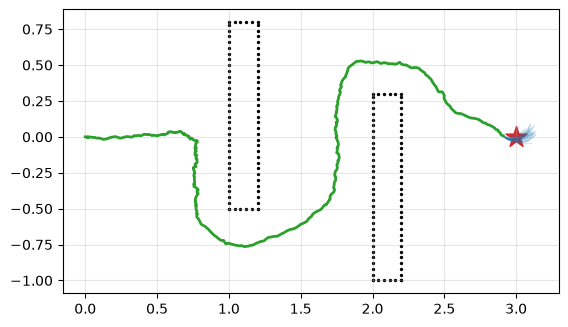

In [6]:
import numpy as np
import matplotlib.pyplot as plt

def wall(x0, y0, x1, y1, spacing=0.04):       # rectangle outline as points
    xs = np.arange(x0, x1 + 1e-9, spacing); ys = np.arange(y0, y1 + 1e-9, spacing)
    return np.concatenate([np.c_[xs, np.full_like(xs, y0)], np.c_[xs, np.full_like(xs, y1)],
                           np.c_[np.full_like(ys, x0), ys], np.c_[np.full_like(ys, x1), ys]])

obstacles = jnp.array(np.concatenate([wall(1.0, -0.5, 1.2, 0.8), wall(2.0, -1.0, 2.2, 0.3)]))
goal = jnp.array([3.0, 0.0])
state, U, key = jnp.zeros(3), jnp.zeros((H, 2)), jax.random.PRNGKey(0)
rng = np.random.default_rng(0)

path = [np.asarray(state)]
for t in range(400):
    key, u, U, trajs, costs = mppi_step(key, state, U, goal, obstacles)
    state = step(state, u) + jnp.array(rng.normal(0, [0.005, 0.005, 0.01]))  # "real" robot is noisy
    path.append(np.asarray(state))
    if jnp.linalg.norm(state[:2] - goal) < 0.1:
        break

path = np.array(path)
plt.scatter(*np.asarray(obstacles).T, s=2, color="k")
for tr in np.asarray(trajs)[::16]:
    plt.plot(tr[:, 0], tr[:, 1], lw=0.5, alpha=0.3, color="tab:blue")  # last tick's samples
plt.plot(path[:, 0], path[:, 1], lw=2, color="tab:green")
plt.scatter(*goal, marker="*", s=250, color="tab:red")
plt.gca().set_aspect("equal"); plt.grid(alpha=0.3); plt.show()